# Week 1 — Data Ingestion, Causal DAG & Pre-Treatment Baselines
**Project 1 · Causal Inference & Synthetic Control Engine for Algorithmic Pricing**

| Day | Deliverable |
|---|---|
| 1 | Ingest regional transactions + competitor pricing telemetry; validated, cleaned panel |
| 2 | Exploratory analysis: rollout, covariate balance, why naive comparisons fail |
| 3 | Causal DAG (DoWhy): confounders, back-door identification |
| 4 | Treatment vs pre-treatment split; baseline trajectories & pre-trend diagnostics |
| 5 | Persist artefacts, Week-1 checkpoint |

In [1]:
import _bootstrap  # noqa: F401  (adds src/ to sys.path)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cpe.config import CFG
from cpe.data import simulate_raw, ingest, load_ground_truth, primary_market
from cpe import dag
from cpe.utils import setup_style, savefig, save_json

setup_style()
CFG.ensure_dirs()
pd.options.display.float_format = "{:,.4f}".format

## Day 1 — Ingestion & validation
The raw layer mimics three operational sources: weekly **market transactions**, **competitor price
telemetry** (with realistic dropouts, spikes and duplicate pings), and a **pricing-event log**.
To use real data, replace the CSVs in `data/raw/` (schema documented in `cpe/data.py`) and skip the simulator.

In [2]:
sim = simulate_raw(CFG)             # remove this line when using real extracts
panel, report = ingest(CFG)
print("Ingestion report")
print(pd.Series(report.to_dict()).to_string())
panel.head()

Ingestion report
rows_transactions           4160
rows_telemetry_raw          4185
duplicates_removed            25
missing_competitor_price      95
outliers_winsorised           22
panel_balanced              True
n_markets                     40
n_weeks                      104


,week_start,market_id,units_sold,avg_price,gross_revenue,competitor_avg_price,log_pop,income_z,urban_index,comp_intensity,...,dynamic_pricing,event_time,base_price,log_revenue,log_price,comp_gap,comp_gap_4w,seasonality,neighbor_adoption,adjacent_to_treated
0,2023-01-02,R00,"1,023.3000",81.5800,"83,481.8500",87.5900,11.8448,0.2044,0.5905,0.8557,...,0,-63.0000,81.6300,11.3324,4.4016,0.0705,0.0705,0.5646,0.0000,0
1,2023-01-09,R00,"1,011.7000",82.1300,"83,089.6600",88.0500,11.8448,0.2044,0.5905,0.8557,...,0,-62.0000,81.6300,11.3277,4.4083,0.0757,0.0731,0.6600,0.0000,0
2,2023-01-16,R00,"1,036.3000",82.0400,"85,022.4900",89.3600,11.8448,0.2044,0.5905,0.8557,...,0,-61.0000,81.6300,11.3507,4.4072,0.0905,0.0789,0.7458,0.0000,0
3,2023-01-23,R00,"1,068.2000",81.9500,"87,536.9400",88.1350,11.8448,0.2044,0.5905,0.8557,...,0,-60.0000,81.6300,11.3798,4.4061,0.0767,0.0783,0.8206,0.0000,0
4,2023-01-30,R00,"1,046.3000",80.2300,"83,941.9900",88.2200,11.8448,0.2044,0.5905,0.8557,...,0,-59.0000,81.6300,11.3379,4.3849,0.0776,0.0801,0.8835,0.0000,0


**Data-quality gates.** The pipeline fails fast on duplicate keys / non-positive values, de-duplicates
telemetry pings, removes spikes with a rolling-median Hampel filter and linearly interpolates dropouts.

In [3]:
assert report.panel_balanced, "panel must be balanced for the within transformation"
quality = pd.DataFrame({
    "check": ["balanced panel", "duplicate telemetry rows removed", "missing competitor prices (interpolated)",
              "spike outliers replaced", "markets", "weeks"],
    "value": [report.panel_balanced, report.duplicates_removed, report.missing_competitor_price,
              report.outliers_winsorised, report.n_markets, report.n_weeks]})
quality

,check,value
0,balanced panel,True
1,duplicate telemetry rows removed,25
2,missing competitor prices (interpolated),95
3,spike outliers replaced,22
4,markets,40
5,weeks,104


## Day 2 — Exploratory analysis: why a plain A/B read-out fails here

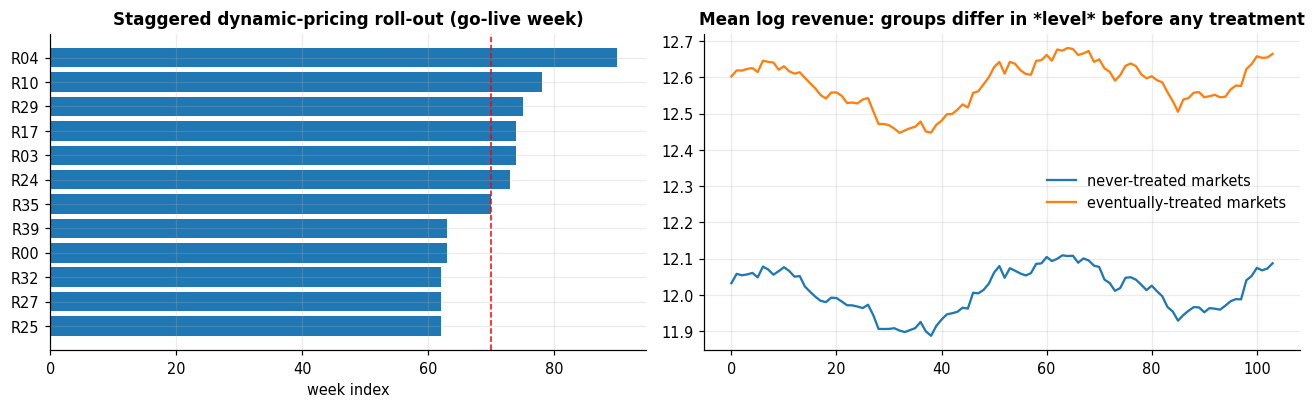

In [4]:
treated = panel[panel.treated_unit == 1]
golive = treated.groupby("market_id")["go_live"].first().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(golive.index, golive.values, color="#1f77b4")
ax[0].axvline(CFG.primary_adoption_week, color="r", ls="--", lw=1)
ax[0].set_title("Staggered dynamic-pricing roll-out (go-live week)")
ax[0].set_xlabel("week index")
g = panel.groupby(["week_idx", "treated_unit"])["log_revenue"].mean().unstack()
ax[1].plot(g.index, g[0], label="never-treated markets")
ax[1].plot(g.index, g[1], label="eventually-treated markets")
ax[1].set_title("Mean log revenue: groups differ in *level* before any treatment")
ax[1].legend()
plt.tight_layout(); savefig(fig, "w1_rollout_and_levels.png"); plt.show()

**Covariate balance** (standardised mean difference, treated vs never-treated markets). |SMD| > 0.25 = imbalance
→ adoption is *not* random, so naive comparisons are confounded.

In [5]:
static = panel.drop_duplicates("market_id").set_index("market_id")
cols = ["log_pop", "income_z", "urban_index", "comp_intensity"]
t, c = static[static.treated_unit == 1][cols], static[static.treated_unit == 0][cols]
smd = ((t.mean() - c.mean()) / np.sqrt((t.var() + c.var()) / 2)).rename("SMD").to_frame()
smd["imbalanced (|SMD|>0.25)"] = smd.SMD.abs() > 0.25
smd

,SMD,imbalanced (|SMD|>0.25)
log_pop,1.4198,True
income_z,0.5840,True
urban_index,2.0715,True
comp_intensity,1.1951,True


In [6]:
post = treated[treated.dynamic_pricing == 1]
never_post = panel[(panel.treated_unit == 0) & (panel.week_idx >= post.week_idx.min())]
naive = post.log_revenue.mean() - never_post.log_revenue.mean()
gt = load_ground_truth(CFG)
truth = panel[panel.dynamic_pricing == 1].merge(gt[["market_id", "true_tau_log"]], on="market_id").true_tau_log.mean()
print(f"Naive treated-vs-control 'lift'       : {naive:+.1%}  (log-points)")
print(f"True average effect (simulation only) : {truth:+.1%}")
print("→ the naive read-out is wildly biased because adopters are larger/urban markets.")

Naive treated-vs-control 'lift'       : +59.1%  (log-points)
True average effect (simulation only) : +4.7%
→ the naive read-out is wildly biased because adopters are larger/urban markets.


## Day 3 — Causal DAG with DoWhy
The DAG encodes our *assumptions*: adoption is driven by market structure and by a smoothed competitor-price
signal; hidden local demand drives both competitor prices and revenue; neighbours' adoption spills over onto revenue.

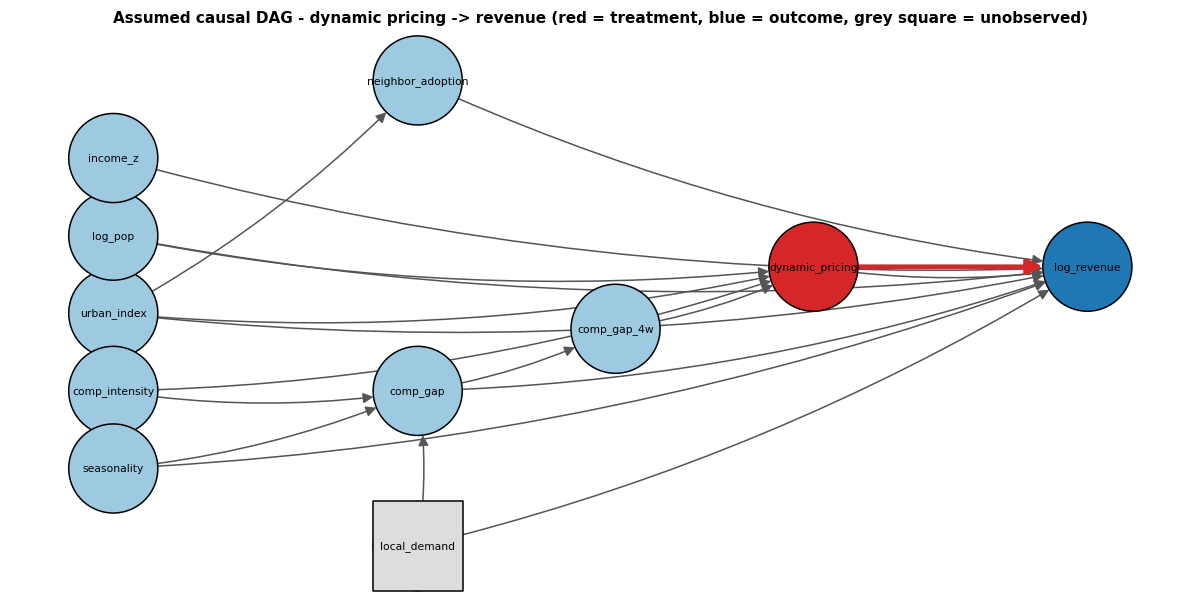

,variable,observed,ancestor_of_treatment,ancestor_of_outcome,confounder
3,comp_gap,True,True,True,True
6,comp_gap_4w,True,True,True,True
2,comp_intensity,True,True,True,True
5,local_demand,False,True,True,True
1,log_pop,True,True,True,True
7,seasonality,True,True,True,True
0,urban_index,True,True,True,True
4,income_z,True,False,True,False
8,neighbor_adoption,True,False,True,False


In [7]:
G = dag.build_dag()
fig = dag.plot_dag(G, CFG.fig_dir / "w1_causal_dag.png"); plt.show()
dag.confounder_report(G)

In [8]:
model, estimand, adjustment_set = dag.identify(panel, G)
print("Back-door adjustment set found by DoWhy:", adjustment_set)
print(estimand)

Back-door adjustment set found by DoWhy: ['comp_gap_4w', 'comp_intensity', 'log_pop', 'urban_index']
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                                                                      ↪
──────────────────(E[log_revenue|comp_gap_4w,log_pop,comp_intensity,urban_inde ↪
d[dynamic_pricing]                                                             ↪

↪    
↪ x])
↪    
Estimand assumption 1, Unconfoundedness: If U→{dynamic_pricing} and U→log_revenue then P(log_revenue|dynamic_pricing,comp_gap_4w,log_pop,comp_intensity,urban_index,U) = P(log_revenue|dynamic_pricing,comp_gap_4w,log_pop,comp_intensity,urban_index)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
        d                                                                  

**Reading the output.** The unobserved `local_demand` is a confounder only through `comp_gap`, which is
observed; conditioning on the competitor signal (`comp_gap` or its smoothed version `comp_gap_4w` —
DoWhy may return either; both are valid minimal back-door sets) blocks that path. This identification
claim is *untestable* from data — Week 3 stress-tests it with sensitivity analysis.

## Day 4 — Treatment vs pre-treatment periods and baselines
For the focal market, history is split into three **non-overlapping** windows:
`train` (fit the synthetic control) → `validation` (blocked, out-of-sample pre-treatment check) → `post`.

Focal market: R35   |   windows (week idx): {'train': (0, 51), 'validation': (52, 69), 'post': (70, 103)}


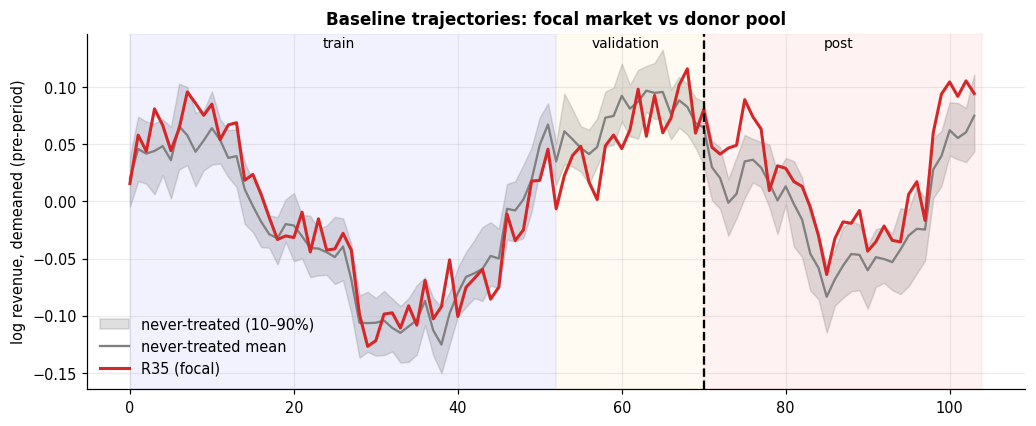

In [9]:
primary = primary_market(CFG)
T0 = CFG.primary_adoption_week
windows = {"train": (0, CFG.train_end - 1), "validation": (CFG.train_end, T0 - 1), "post": (T0, CFG.n_weeks - 1)}
print(f"Focal market: {primary}   |   windows (week idx): {windows}")

Y = panel.pivot(index="week_idx", columns="market_id", values="log_revenue")
never = [m for m in Y.columns if m not in set(treated.market_id)]
Yd = Y - Y.iloc[:T0].mean()                       # deviations from own pre-period level
band_lo, band_hi = Yd[never].quantile(0.1, axis=1), Yd[never].quantile(0.9, axis=1)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(Yd.index, band_lo, band_hi, color="grey", alpha=0.25, label="never-treated (10–90%)")
ax.plot(Yd.index, Yd[never].mean(1), color="grey", lw=1.5, label="never-treated mean")
ax.plot(Yd.index, Yd[primary], color="#d62728", lw=2, label=f"{primary} (focal)")
for k, (a, b) in windows.items():
    ax.axvspan(a, b + 1, alpha=0.05, color={"train": "b", "validation": "orange", "post": "r"}[k])
    ax.text((a + b) / 2, ax.get_ylim()[1] * 0.92, k, ha="center", fontsize=9)
ax.axvline(T0, color="k", ls="--"); ax.set_ylabel("log revenue, demeaned (pre-period)")
ax.set_title("Baseline trajectories: focal market vs donor pool"); ax.legend(loc="lower left")
savefig(fig, "w1_baseline_trajectories.png"); plt.show()

**Pre-treatment diagnostics.** (1) Is the focal-vs-donor gap stationary before treatment (ADF)?
(2) Is there a differential pre-trend? (3) Strength of seasonality (STL).

In [10]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL

gap_pre = (Yd[primary] - Yd[never].mean(1)).iloc[:T0]
adf_stat, adf_p, *_ = adfuller(gap_pre, regression="c", autolag="AIC")
slope, intercept = np.polyfit(np.arange(T0), gap_pre.to_numpy(), 1)
stl = STL(Y[primary].iloc[:T0], period=52, robust=True).fit()
seas_strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
diag = pd.Series({"ADF statistic (gap)": adf_stat, "ADF p-value": adf_p,
                  "pre-trend slope (log-pts / week)": slope,
                  "seasonal strength (STL, 0-1)": seas_strength})
print(diag.round(4).to_string())

ADF statistic (gap)                -1.9242
ADF p-value                         0.3208
pre-trend slope (log-pts / week)   -0.0006
seasonal strength (STL, 0-1)        0.9689


## Day 5 — Persist artefacts & Week-1 checkpoint

In [11]:
save_json({"primary": primary, "t0": T0, "windows": windows, "never_treated": never,
           "treated": sorted(treated.market_id.unique()), "adjustment_set": adjustment_set,
           "ingest_report": report.to_dict(), "naive_lift_log": naive, "diagnostics": diag.to_dict()},
          "week1_summary.json")

checklist = pd.DataFrame({"Week-1 requirement": [
    "Ingest regional market transaction datasets & competitor pricing telemetry",
    "Construct DAG with DoWhy, map relationships, identify confounders",
    "Separate treatment period from pre-treatment learning period; baseline trajectories"],
    "Evidence": ["data/processed/panel.csv, results/week1_summary.json",
                 "reports/figures/w1_causal_dag.png + DoWhy adjustment set",
                 "reports/figures/w1_baseline_trajectories.png (train / validation / post)"],
    "Status": ["✅", "✅", "✅"]})
checklist

,Week-1 requirement,Evidence,Status
0,Ingest regional market transaction datasets & ...,"data/processed/panel.csv, results/week1_summar...",✅
1,"Construct DAG with DoWhy, map relationships, i...",reports/figures/w1_causal_dag.png + DoWhy adju...,✅
2,Separate treatment period from pre-treatment l...,reports/figures/w1_baseline_trajectories.png (...,✅
